#  ⚠️ Risk Alert Classifier

# 🧪 Part B: Dataset Understanding & Preparation

### 1 Load liabaries and Dataset

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
df = pd.read_csv("Risk_Alert_Classifier_Dataset_4600.csv")

In [3]:
df.head()

,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


In [4]:
print("Columns:", df.columns.tolist())

Columns: ['customer_id', 'age', 'gender', 'region', 'employment_type', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'last_transaction_date', 'debt_balance_inr', 'risk_status']


In [5]:
df.shape

(4600, 19)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         4600 non-null   int64

In [7]:
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

customer_id                    0
age                          140
gender                         0
region                       102
employment_type              144
annual_income_inr            166
credit_score                 216
credit_utilization_ratio     147
missed_payments_12m            0
avg_late_payment_days          0
monthly_transaction_count      0
monthly_spend_inr            129
cash_advance_count_6m          0
complaints_last_6m             0
failed_login_attempts_3m       0
account_tenure_months          0
last_transaction_date          0
debt_balance_inr               0
risk_status                    0
dtype: int64
Total missing values: 1044


In [8]:
df.columns.tolist()

['customer_id',
 'age',
 'gender',
 'region',
 'employment_type',
 'annual_income_inr',
 'credit_score',
 'credit_utilization_ratio',
 'missed_payments_12m',
 'avg_late_payment_days',
 'monthly_transaction_count',
 'monthly_spend_inr',
 'cash_advance_count_6m',
 'complaints_last_6m',
 'failed_login_attempts_3m',
 'account_tenure_months',
 'last_transaction_date',
 'debt_balance_inr',
 'risk_status']

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
target = "risk_status" 

X = df.drop(columns=[target])
y = df[target]

print("Input features:", X.columns.tolist())
print("Target distribution:")
print(y.value_counts())

Input features: ['customer_id', 'age', 'gender', 'region', 'employment_type', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'last_transaction_date', 'debt_balance_inr']
Target distribution:
risk_status
0    4043
1     557
Name: count, dtype: int64


### Step 7: Train–Test Split (80:20)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True))

Training data: (3680, 18)
Testing data: (920, 18)

Training class distribution:
risk_status
0    0.878804
1    0.121196
Name: proportion, dtype: float64

Testing class distribution:
risk_status
0    0.879348
1    0.120652
Name: proportion, dtype: float64


In [12]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Identify column types from training data
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", KNNImputer(n_neighbors=5)),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, num_cols),
    ("categorical", categorical_pipeline, cat_cols)
])

# Full pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train and predict
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Complete pipeline trained successfully!")


Complete pipeline trained successfully!


### Missing Values + KNN Imputer

In [13]:
print("Missing values in each column:")
print(X_train.isnull().sum())

print("\nTotal missing values:", X_train.isnull().sum().sum())

Missing values in each column:
customer_id                    0
age                          116
gender                         0
region                        78
employment_type              115
annual_income_inr            132
credit_score                 181
credit_utilization_ratio     118
missed_payments_12m            0
avg_late_payment_days          0
monthly_transaction_count      0
monthly_spend_inr            110
cash_advance_count_6m          0
complaints_last_6m             0
failed_login_attempts_3m       0
account_tenure_months          0
last_transaction_date          0
debt_balance_inr               0
dtype: int64

Total missing values: 850


### Knn Imputer Apply

In [14]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# Numerical columns only
num_cols = X_train.select_dtypes(include="number").columns

# Scale numerical features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train[num_cols])
X_test_scaled = scaler.transform(X_test[num_cols])

# Apply KNN Imputer
imputer = KNNImputer(n_neighbors=5)

X_train_imputed = imputer.fit_transform(X_train_scaled)
X_test_imputed = imputer.transform(X_test_scaled)

print("Missing values after imputation:",
      pd.DataFrame(X_train_imputed).isnull().sum().sum())

print("Training shape after imputation:", X_train_imputed.shape)
print("Testing shape after imputation:", X_test_imputed.shape)

Missing values after imputation: 0
Training shape after imputation: (3680, 14)
Testing shape after imputation: (920, 14)


## 📊 Part C: Baseline Classification Model

### Logical Regresion Model Import

In [15]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_imputed, y_train)

y_pred = model.predict(X_test_imputed)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### Confusion Matrix aur performance metrics

In [16]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:\n", cm)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-Score:", f1_score(y_test, y_pred, zero_division=0))

Confusion Matrix:
 [[809   0]
 [  0 111]]
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0


<!-- Type-I aur Type-II errors identify karo  -->

### Type-I aur Type-II errors identify karo

In [17]:
tn, fp, fn, tp = cm.ravel()

print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

print("Type-I Error (FP):", fp)
print("Type-II Error (FN):", fn)

True Negative (TN): 809
False Positive (FP): 0
False Negative (FN): 0
True Positive (TP): 111
Type-I Error (FP): 0
Type-II Error (FN): 0


# ⚖️ Part D: Handling Imbalanced Data

## Class imbalance

Full dataset class counts:
risk_status
0    4043
1     557
Name: count, dtype: int64

Class percentages:
risk_status
0    87.89
1    12.11
Name: proportion, dtype: float64


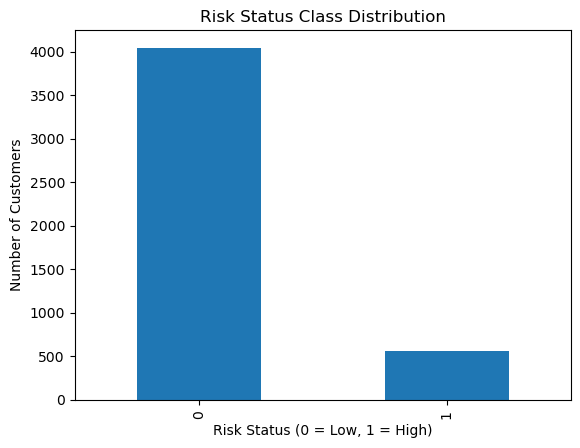

In [18]:
import matplotlib.pyplot as plt

print("Full dataset class counts:")
print(y.value_counts())

print("\nClass percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

y.value_counts().sort_index().plot(
    kind="bar",
    title="Risk Status Class Distribution"
)
plt.xlabel("Risk Status (0 = Low, 1 = High)")
plt.ylabel("Number of Customers")
plt.show()

In [19]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

from sklearn.metrics import recall_score, f1_score, roc_auc_score

# Identify numerical and categorical features
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

# Numerical preprocessing
num_pipe = SkPipeline([
    ("imputer", KNNImputer(n_neighbors=5)),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
cat_pipe = SkPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
], verbose_feature_names_out=False)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


### 14 Apply the following techniques and retrain the model:
#### Under-Sampling
#### Over-Sampling
#### SMOTE
#### ADASYN


In [20]:
samplers = {
    "Baseline": "passthrough",
    "Under-Sampling": RandomUnderSampler(random_state=42),
    "Over-Sampling": RandomOverSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42, k_neighbors=5),
    "ADASYN": ADASYN(random_state=42, n_neighbors=5)
}

results = []

for name, sampler in samplers.items():

    model = ImbPipeline([
        ("preprocessor", preprocessor),
        ("sampler", sampler),
        ("classifier", LogisticRegression(max_iter=2000))
    ])

    try:
        # Resampling happens only during training
        model.fit(X_train, y_train)

        # Test data remains unchanged
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        results.append({
            "Method": name,
            "Minority Recall": recall_score(
                y_test, y_pred, pos_label=1, zero_division=0
            ),
            "F1-Score": f1_score(
                y_test, y_pred, pos_label=1, zero_division=0
            ),
            "AUC-ROC": roc_auc_score(y_test, y_prob)
        })

    except (ValueError, RuntimeError) as e:
        print(f"{name} could not run: {e}")

results_df = pd.DataFrame(results)
print(results_df.round(4))

C:\Users\rosha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\rosha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\rosha\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\rosha\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

           Method  Minority Recall  F1-Score  AUC-ROC
0        Baseline              1.0    1.0000      1.0
1  Under-Sampling              1.0    0.9823      1.0
2   Over-Sampling              1.0    1.0000      1.0
3           SMOTE              1.0    0.9955      1.0
4          ADASYN              1.0    0.9867      1.0


#### Compare performance before and after balancing using:

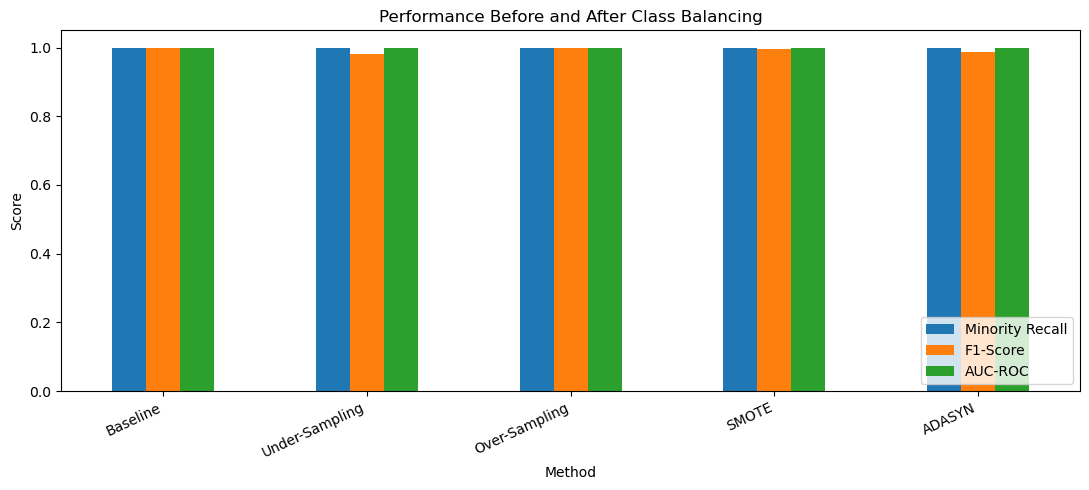

In [21]:
results_df = results_df.set_index("Method")

results_df[
    ["Minority Recall", "F1-Score", "AUC-ROC"]
].plot(kind="bar", figsize=(11, 5), ylim=(0, 1.05))

plt.title("Performance Before and After Class Balancing")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

<!-- 🌳 Part E: Tree-Based Classification Models -->

# 🌳 Part E: Tree-Based Classification Models

### 16: Decision Tree Classifier

In [22]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create and train Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_imputed, y_train)

# Predictions
dt_train_pred = dt_model.predict(X_train_imputed)
dt_test_pred = dt_model.predict(X_test_imputed)

print("Decision Tree Training Accuracy:",
      accuracy_score(y_train, dt_train_pred))

print("Decision Tree Testing Accuracy:",
      accuracy_score(y_test, dt_test_pred))


Decision Tree Training Accuracy: 1.0
Decision Tree Testing Accuracy: 0.9717391304347827


### 17 Overfitting analyze

In [23]:
train_acc = accuracy_score(y_train, dt_train_pred)
test_acc = accuracy_score(y_test, dt_test_pred)

print("Training Accuracy:", round(train_acc, 4))
print("Testing Accuracy:", round(test_acc, 4))
print("Accuracy Gap:", round(train_acc - test_acc, 4))

Training Accuracy: 1.0
Testing Accuracy: 0.9717
Accuracy Gap: 0.0283


### Random Forest Classifier

In [24]:

from sklearn.ensemble import RandomForestClassifier

# Create and train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_imputed, y_train)

# Predictions
rf_train_pred = rf_model.predict(X_train_imputed)
rf_test_pred = rf_model.predict(X_test_imputed)

print("Random Forest Training Accuracy:",
      accuracy_score(y_train, rf_train_pred))

print("Random Forest Testing Accuracy:",
      accuracy_score(y_test, rf_test_pred))


Random Forest Training Accuracy: 1.0
Random Forest Testing Accuracy: 0.9967391304347826


### Decision Tree vs Random Forest comparison

In [25]:

comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Training Accuracy": [
        accuracy_score(y_train, dt_train_pred),
        accuracy_score(y_train, rf_train_pred)
    ],
    "Testing Accuracy": [
        accuracy_score(y_test, dt_test_pred),
        accuracy_score(y_test, rf_test_pred)
    ]
})

comparison["Accuracy Gap"] = (
    comparison["Training Accuracy"]
    - comparison["Testing Accuracy"]
)

print(comparison.round(4))


           Model  Training Accuracy  Testing Accuracy  Accuracy Gap
0  Decision Tree                1.0            0.9717        0.0283
1  Random Forest                1.0            0.9967        0.0033


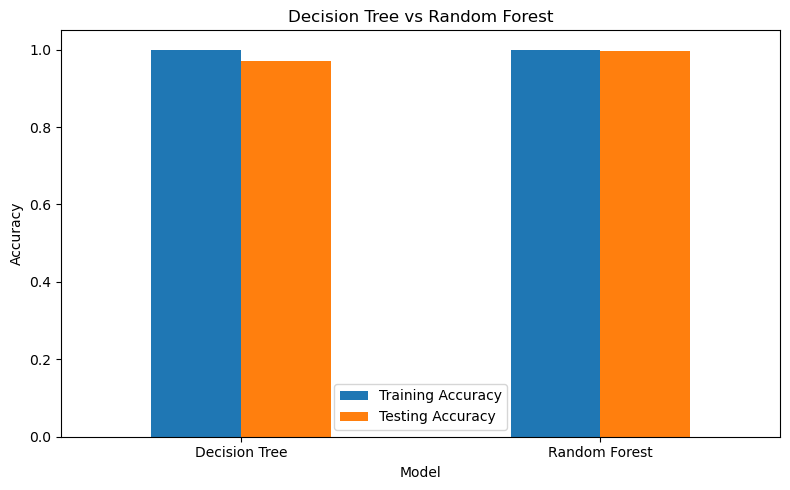

In [26]:
comparison.set_index("Model")[
    ["Training Accuracy", "Testing Accuracy"]
].plot(kind="bar", ylim=(0, 1.05), figsize=(8, 5))

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Accuracy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Part F: Hyperparameter Tuning

In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.metrics import accuracy_score, recall_score, f1_score
import pandas as pd

### Decision Tree par Randomized Search CV

In [28]:
dt_params = {
    "max_depth": [3, 5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "criterion": ["gini", "entropy"]
}

dt_random = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=dt_params,
    n_iter=20,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

dt_random.fit(X_train_imputed, y_train)

print("Best Decision Tree Parameters:")
print(dt_random.best_params_)
print("Best CV F1-Score:", dt_random.best_score_)

Best Decision Tree Parameters:
{'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 20, 'criterion': 'gini'}
Best CV F1-Score: 0.8987024960444019


### Random Forest par Randomized Search CV

In [29]:
rf_params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_random = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=1),
    param_distributions=rf_params,
    n_iter=20,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

rf_random.fit(X_train_imputed, y_train)

print("Best Random Forest Parameters:")
print(rf_random.best_params_)
print("Best CV F1-Score:", rf_random.best_score_)

Best Random Forest Parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}
Best CV F1-Score: 0.9587806190108482


### Best model par Grid Search CV

In [30]:
best_rf_params = rf_random.best_params_

grid_params = {
    "n_estimators": sorted(set([
        100,
        best_rf_params["n_estimators"],
        300
    ])),
    "max_depth": list(dict.fromkeys([
        best_rf_params["max_depth"],
        10,
        None
    ])),
    "min_samples_split": sorted(set([
        best_rf_params["min_samples_split"],
        2,
        5
    ])),
    "min_samples_leaf": sorted(set([
        best_rf_params["min_samples_leaf"],
        1,
        2
    ])),
    "max_features": [best_rf_params["max_features"]]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_grid=grid_params,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

rf_grid.fit(X_train_imputed, y_train)

print("Best Grid Search Parameters:")
print(rf_grid.best_params_)
print("Best CV F1-Score:", rf_grid.best_score_)

Best Grid Search Parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Best CV F1-Score: 0.9610131352037135


### campare Tuned and Untuned

In [31]:
models = {
    "Untuned Decision Tree": DecisionTreeClassifier(random_state=42),
    "Tuned Decision Tree": dt_random.best_estimator_,
    "Untuned Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "Tuned Random Forest": rf_grid.best_estimator_
}

results = []

for name, model in models.items():
    if "Untuned" in name:
        model.fit(X_train_imputed, y_train)

    pred = model.predict(X_test_imputed)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "High Risk Recall": recall_score(
            y_test, pred, pos_label=1, zero_division=0
        ),
        "High Risk F1": f1_score(
            y_test, pred, pos_label=1, zero_division=0
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

                   Model  Accuracy  High Risk Recall  High Risk F1
0  Untuned Decision Tree    0.9717            0.8288        0.8762
1    Tuned Decision Tree    0.9793            0.8739        0.9108
2  Untuned Random Forest    0.9967            0.9820        0.9864
3    Tuned Random Forest    0.9978            0.9910        0.9910


# 📈 Part G: Model Evaluation & ROC Analysis

### ROC Curve for all models

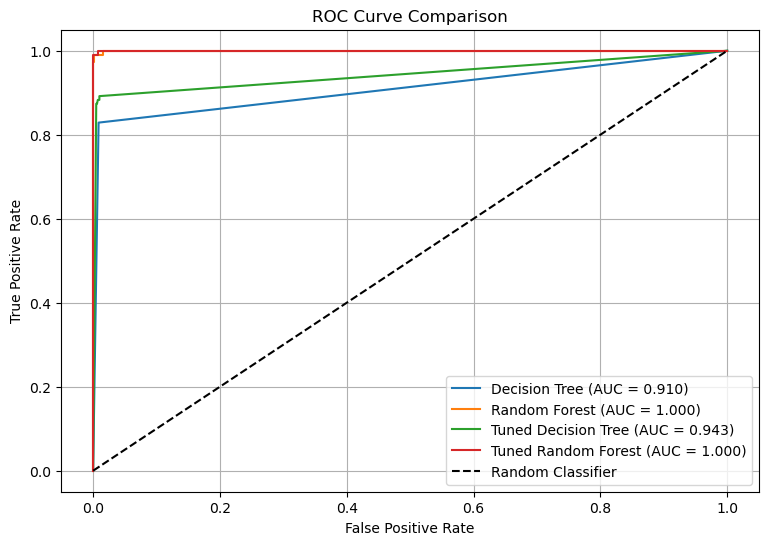

In [32]:

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    recall_score,
    f1_score
)

models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Tuned Decision Tree": dt_random.best_estimator_,
    "Tuned Random Forest": rf_grid.best_estimator_
}

plt.figure(figsize=(9, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test_imputed)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()


### AUC-ROC scores compare karo

In [33]:

auc_results = []

for name, model in models.items():
    y_prob = model.predict_proba(X_test_imputed)[:, 1]

    auc_results.append({
        "Model": name,
        "AUC-ROC": roc_auc_score(y_test, y_prob)
    })

auc_df = pd.DataFrame(auc_results).sort_values(
    by="AUC-ROC", ascending=False
)

print(auc_df.round(4))


                 Model  AUC-ROC
3  Tuned Random Forest   0.9999
1        Random Forest   0.9998
2  Tuned Decision Tree   0.9431
0        Decision Tree   0.9101


### Minimum False Negatives ke basis par final model

In [34]:

final_results = []

for name, model in models.items():
    y_pred = model.predict(X_test_imputed)
    y_prob = model.predict_proba(X_test_imputed)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    final_results.append({
        "Model": name,
        "False Negatives": fn,
        "High Risk Recall": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "AUC-ROC": roc_auc_score(y_test, y_prob)
    })

final_df = pd.DataFrame(final_results).sort_values(
    by=["False Negatives", "High Risk Recall", "AUC-ROC"],
    ascending=[True, False, False]
)

print(final_df.round(4))

best_model_name = final_df.iloc[0]["Model"]
print("\nSelected model:", best_model_name)


                 Model  False Negatives  High Risk Recall  F1-Score  AUC-ROC
3  Tuned Random Forest                1            0.9910    0.9910   0.9999
1        Random Forest                2            0.9820    0.9864   0.9998
2  Tuned Decision Tree               14            0.8739    0.9108   0.9431
0        Decision Tree               19            0.8288    0.8762   0.9101

Selected model: Tuned Random Forest


# 🧾 Part H: Final Analysis & Reporting

###  Final report prepare

### 26.1 Best classification model and justification
Final model ko final_df ke results se select karo.
- Primary priority: False Negatives (FN) minimum hona chahiye.
- Secondary priority: High Risk Recall aur F1-Score achhe hone chahiye.
- Additional metric: AUC-ROC se models ki classification ability compare karo.
Actual evaluation results ke bina kisi model ko best declare karna sahi nahi hoga.
### 26.2 Imbalance handling techniques ka impact
Technique	Impact
Under-Sampling	Majority class ke samples reduce karta hai
Over-Sampling	Minority class ke samples duplicate karta hai
SMOTE	Synthetic minority samples generate karta hai
ADASYN	Difficult minority examples par zyada focus karta hai
In techniques ka actual impact tumhare Part D ke Recall, F1-Score aur AUC-ROC results se report karna hai.

### Performance camparision table

In [35]:
# Part D results: results_df
# Part G results: final_df

print("Imbalance Handling Results:")
print(results_df.round(4))

print("\nFinal Model Comparison:")
print(final_df.round(4))

Imbalance Handling Results:
                   Model  Accuracy  High Risk Recall  High Risk F1
0  Untuned Decision Tree    0.9717            0.8288        0.8762
1    Tuned Decision Tree    0.9793            0.8739        0.9108
2  Untuned Random Forest    0.9967            0.9820        0.9864
3    Tuned Random Forest    0.9978            0.9910        0.9910

Final Model Comparison:
                 Model  False Negatives  High Risk Recall  F1-Score  AUC-ROC
3  Tuned Random Forest                1            0.9910    0.9910   0.9999
1        Random Forest                2            0.9820    0.9864   0.9998
2  Tuned Decision Tree               14            0.8739    0.9108   0.9431
0        Decision Tree               19            0.8288    0.8762   0.9101


### 26.4 Business interpretation of errors
Error	Business meaning	Possible impact
False Positive (Type-I)	Low Risk customer ko High Risk classify karna	Unnecessary review, delay ya customer inconvenience
False Negative (Type-II)	High Risk customer ko Low Risk classify karna	Risky customer miss ho sakta hai aur financial loss ho sakta hai
Recommendation: Credit-risk use case mein False Negatives ko minimize karna important hai, lekin threshold aisa choose karna chahiye jo False Positives aur operational costs ko bhi consider kare.

# Import Model

In [38]:
# Best model based on minimum False Negatives,
# then highest Recall, followed by AUC-ROC

best_model_name = final_df.sort_values(
    by=["False Negatives", "High Risk Recall", "AUC-ROC"],
    ascending=[True, False, False]
).iloc[0]["Model"]

best_model = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Tuned Random Forest


In [39]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(best_model, "models/best_model.joblib")

print("Model saved successfully!")
print("Model location:", os.path.abspath("models/best_model.joblib"))

Model saved successfully!
Model location: C:\Users\rosha\Suparvised 2.0\models\best_model.joblib


In [44]:
import joblib
from pathlib import Path

model_dir = Path(r"C:\Users\rosha\Suparvised 2.0\models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(scaler, model_dir / "scaler.joblib")

['C:\\Users\\rosha\\Suparvised 2.0\\models\\scaler.joblib']

In [45]:
joblib.dump(imputer, model_dir / "imputer.joblib")

['C:\\Users\\rosha\\Suparvised 2.0\\models\\imputer.joblib']